# AgriSignal: can a model call the direction of prices?

The models predict whether the wheat or paddy price will be higher 1, 2 or 3 months later. They are tested walk-forward with `src/train_models.py`: for every month from January 2012 the model is retrained on all earlier months whose outcome was already known, and then makes one prediction. That is how it would have done if it had been used live.

Two models, each with two sets of inputs:

- **logistic regression**: simple and explainable
- **XGBoost**: small, slow-learning trees, to see whether a non-linear model finds more
- **base** inputs: the calendar month and the last two monthly price changes (momentum)
- **base + NDVI**: the same plus the crop health anomaly this month and last month

Comparing base with base + NDVI shows directly what the satellite data adds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path("..") / "src"))
from baselines import future_up
from train_models import FEATURE_SETS, add_model_inputs, summarise

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 160)

predictions = pd.read_csv(Path("..") / "data" / "processed" / "predictions.csv")
summary = summarise(predictions)
predictions.groupby(["crop", "months_ahead"])["month"].agg(["min", "max", "count"])

min      max  count
crop  months_ahead                         
paddy 1             2012-01  2026-08    176
      2             2012-01  2026-07    175
      3             2012-01  2026-06    174
wheat 1             2012-01  2026-08    176
      2             2012-01  2026-07    175
      3             2012-01  2026-06    174

## 1. Accuracy against the best simple rule

For each crop and horizon the bar is whichever simple rule (always up, calendar or momentum) did best on these same months. That choice is made with hindsight, so it is a tough bar. McNemar's test checks whether the months where the model and the rule disagree split more unevenly than a coin flip.

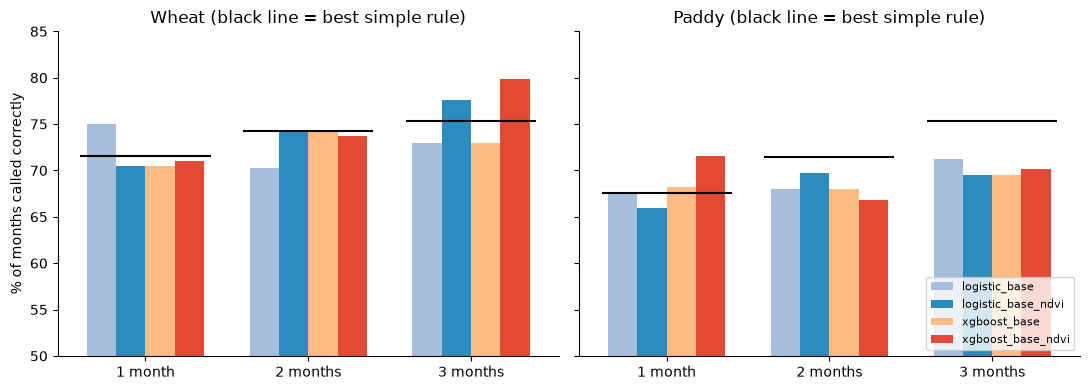

,crop,months_ahead,model,accuracy,best_rule,rule_accuracy,difference,mcnemar_p
0,paddy,1,logistic_base,0.676,calendar,0.676,0.000,1.000
1,paddy,1,xgboost_base,0.682,calendar,0.676,0.006,1.000
2,paddy,1,logistic_base_ndvi,0.659,calendar,0.676,-0.017,0.736
3,paddy,1,xgboost_base_ndvi,0.716,calendar,0.676,0.040,0.189
4,paddy,2,logistic_base,0.680,always_up,0.714,-0.034,0.307
5,paddy,2,xgboost_base,0.680,always_up,0.714,-0.034,0.286
6,paddy,2,logistic_base_ndvi,0.697,always_up,0.714,-0.017,0.701
7,paddy,2,xgboost_base_ndvi,0.669,always_up,0.714,-0.046,0.096
8,paddy,3,logistic_base,0.713,always_up,0.753,-0.040,0.039
9,paddy,3,xgboost_base,0.695,always_up,0.753,-0.057,0.006


In [2]:
accuracy = summary.pivot_table(index=["crop", "months_ahead"], columns="model", values="accuracy")
rules = summary.groupby(["crop", "months_ahead"])[["best_rule", "rule_accuracy"]].first()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {"logistic_base": "#a6bddb", "logistic_base_ndvi": "#2b8cbe",
          "xgboost_base": "#fdbb84", "xgboost_base_ndvi": "#e34a33"}
for ax, crop in zip(axes, ["wheat", "paddy"]):
    width = 0.18
    for offset, model in zip([-1.5, -0.5, 0.5, 1.5], colors):
        values = accuracy.loc[crop, model] * 100
        ax.bar(values.index + offset * width, values, width, color=colors[model], label=model)
    for horizon, row in rules.loc[crop].iterrows():
        ax.hlines(row["rule_accuracy"] * 100, horizon - 0.4, horizon + 0.4, color="black")
    ax.set_xticks([1, 2, 3], ["1 month", "2 months", "3 months"])
    ax.set_ylim(50, 85)
    ax.set_title(f"{crop.title()} (black line = best simple rule)")
axes[0].set_ylabel("% of months called correctly")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

summary[["crop", "months_ahead", "model", "accuracy", "best_rule", "rule_accuracy", "difference", "mcnemar_p"]].round(3)

## 2. What does NDVI add?

The same model with and without the NDVI inputs. Besides accuracy, I use the **Brier score**: the squared gap between the predicted probability of a rise and what happened (lower is better). It rewards being confident when right, so it notices improvements that a plain right or wrong count misses.

In [3]:
rows = []
for (crop, horizon, model), data in summary.assign(
    family=summary["model"].str.split("_").str[0]
).groupby(["crop", "months_ahead", "family"]):
    base = data[~data["model"].str.endswith("ndvi")].iloc[0]
    ndvi = data[data["model"].str.endswith("ndvi")].iloc[0]
    rows.append({"crop": crop, "months_ahead": horizon, "model": model,
                 "accuracy_base": base["accuracy"], "accuracy_with_ndvi": ndvi["accuracy"],
                 "brier_base": base["brier"], "brier_with_ndvi": ndvi["brier"]})
pd.DataFrame(rows).round(3)

,crop,months_ahead,model,accuracy_base,accuracy_with_ndvi,brier_base,brier_with_ndvi
0,paddy,1,logistic,0.676,0.659,0.203,0.208
1,paddy,1,xgboost,0.682,0.716,0.209,0.213
2,paddy,2,logistic,0.680,0.697,0.199,0.203
3,paddy,2,xgboost,0.680,0.669,0.201,0.206
4,paddy,3,logistic,0.713,0.695,0.186,0.196
5,paddy,3,xgboost,0.695,0.701,0.192,0.196
6,wheat,1,logistic,0.750,0.705,0.183,0.188
7,wheat,1,xgboost,0.705,0.710,0.190,0.188
8,wheat,2,logistic,0.703,0.743,0.187,0.183
9,wheat,2,xgboost,0.743,0.737,0.174,0.179


## 3. Probability forecasts against the calendar

The calendar rule can also give a probability: the share of past years in which the price rose from this calendar month. A Wilcoxon signed-rank test compares the model's monthly Brier scores with the calendar's.

In [4]:
brier = summary.pivot_table(index=["crop", "months_ahead"], columns="model", values="brier_p")
brier.insert(0, "calendar_brier", summary.groupby(["crop", "months_ahead"])["calendar_brier"].first())
print("p-values: is the model's Brier score different from the calendar's?")
brier.round(3)

p-values: is the model's Brier score different from the calendar's?


model               calendar_brier  logistic_base  logistic_base_ndvi  xgboost_base  xgboost_base_ndvi
crop  months_ahead                                                                                    
paddy 1                      0.232          0.199               0.183         0.245              0.597
      2                      0.209          0.763               0.775         0.592              0.312
      3                      0.194          0.589               0.843         0.780              0.477
wheat 1                      0.220          0.020               0.023         0.043              0.009
      2                      0.190          0.753               0.574         0.607              0.544
      3                      0.173          0.895               0.044         0.628              0.016

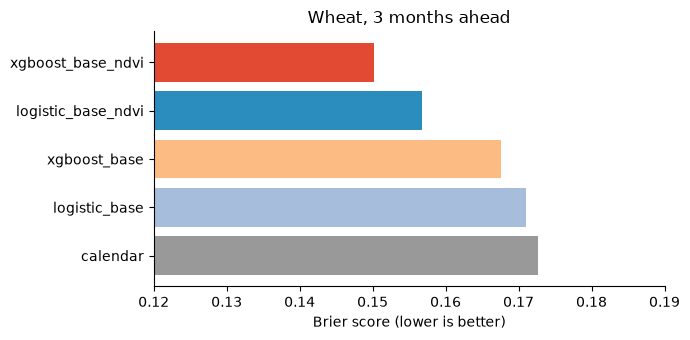

In [5]:
wheat3 = summary[(summary["crop"] == "wheat") & (summary["months_ahead"] == 3)]
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = ["calendar"] + list(wheat3["model"])
values = [wheat3["calendar_brier"].iloc[0]] + list(wheat3["brier"])
ax.barh(labels, values, color=["#999999", "#a6bddb", "#fdbb84", "#2b8cbe", "#e34a33"])
ax.set_xlabel("Brier score (lower is better)")
ax.set_xlim(0.12, 0.19)
ax.set_title("Wheat, 3 months ahead")
plt.tight_layout()
plt.show()

## 4. Is the wheat result steady over time?

A model can look good on average because of one lucky stretch. This is the share of months called correctly over the previous two years, for wheat 3 months ahead.

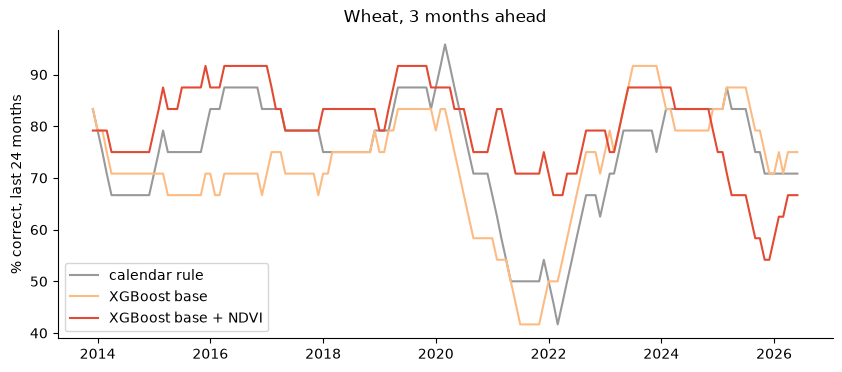

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
calendar,1.0,0.67,0.67,0.92,0.75,0.83,0.75,0.92,0.50,0.58,0.67,0.83,0.83,0.58,0.83
xgboost_base_ndvi,1.0,0.58,0.92,0.92,0.92,0.67,1.00,0.75,0.75,0.75,0.83,0.92,0.67,0.42,1.00


In [6]:
wheat3 = predictions[(predictions["crop"] == "wheat") & (predictions["months_ahead"] == 3)].copy()
wheat3["date"] = pd.to_datetime(wheat3["month"])
fig, ax = plt.subplots(figsize=(10, 4))
for column, color, label in [("calendar", "#999999", "calendar rule"),
                             ("xgboost_base", "#fdbb84", "XGBoost base"),
                             ("xgboost_base_ndvi", "#e34a33", "XGBoost base + NDVI")]:
    rolling = (wheat3[column] == wheat3["outcome"]).rolling(24).mean() * 100
    ax.plot(wheat3["date"], rolling, color=color, label=label)
ax.set_ylabel("% correct, last 24 months")
ax.set_title("Wheat, 3 months ahead")
ax.legend()
plt.show()

by_year = wheat3.assign(year=wheat3["date"].dt.year)
by_year.groupby("year").apply(lambda d: pd.Series({
    "calendar": (d["calendar"] == d["outcome"]).mean(),
    "xgboost_base_ndvi": (d["xgboost_base_ndvi"] == d["outcome"]).mean()}), include_groups=False).round(2).T

## 5. What the logistic model learned

A logistic regression fitted on all wheat months (3 months ahead), with inputs scaled to the same units so the coefficients can be compared. Positive means the input raises the chance of a price rise.

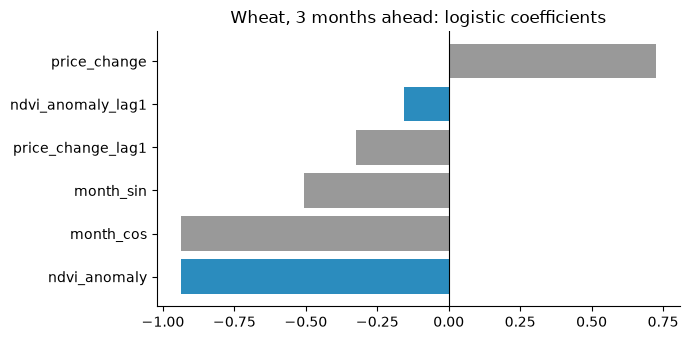

ndvi_anomaly        -0.938
month_cos           -0.936
month_sin           -0.505
price_change_lag1   -0.325
ndvi_anomaly_lag1   -0.157
price_change         0.726
dtype: float64

In [7]:
features = pd.read_csv(Path("..") / "data" / "processed" / "features_monthly.csv")
wheat = add_model_inputs(features[features["crop"] == "wheat"].sort_values("month").reset_index(drop=True))
wheat["outcome"] = future_up(wheat["wpi"], 3)
columns = FEATURE_SETS["base_ndvi"]
data = wheat.dropna(subset=columns + ["outcome"])
model = LogisticRegression(C=1.0).fit(StandardScaler().fit_transform(data[columns]), data["outcome"])
coefficients = pd.Series(model.coef_[0], index=columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(coefficients.index, coefficients, color=["#2b8cbe" if "ndvi" in name else "#999999" for name in coefficients.index])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Wheat, 3 months ahead: logistic coefficients")
plt.tight_layout()
plt.show()
coefficients.round(3)

## What I found

**Wheat, 3 months ahead: crop health makes the forecast better.** Adding NDVI to the same model raises accuracy from 73.0% to 79.9% (XGBoost) and 77.6% (logistic), against 75.3% for the calendar rule. In probability terms, only the models with NDVI beat the calendar by more than chance (Brier score 0.150 against 0.173, p = 0.016 for XGBoost; p = 0.044 for logistic). The same models without NDVI do not (p = 0.63 and 0.90). In the logistic model, the NDVI anomaly has the largest weight of any input, in the expected direction: greener than recent years means a lower chance of a price rise.

**But the accuracy gain over the best simple rule is not proven.** +4.6 percentage points on 174 months has p = 0.24 in McNemar's test, so it could still be luck. With this many comparisons (24 model and horizon pairs), even the probability result is suggestive rather than conclusive.

**The edge is not steady.** By year, the NDVI model beats the calendar rule in 7 of 15 years, loses in 5 and ties in 3. It held up in 2020 to 2022, when the calendar rule fell to around 45% (COVID and then the 2022 heatwave and export ban), but did poorly in 2025.

**Wheat, 1 and 2 months ahead: no gain from NDVI.** At 1 month, momentum does the work and every model's probabilities beat the calendar's, with or without NDVI. At 2 months nothing beats the calendar. This fits how crops work: NDVI describes the crop in the field, and that reaches prices when the harvest comes to market, a few months later.

**Paddy: nothing beats the simple rules.** At 3 months every model is significantly worse than "always up" (p = 0.006 to 0.039), because paddy prices rose in about 75% of 3-month windows and the models occasionally call a fall. NDVI adds nothing for paddy, in line with the Granger tests.

**XGBoost vs logistic regression.** XGBoost is slightly better with NDVI at 3 months, but the two are close everywhere, so the simple model is enough at this data size.

## In one line

Satellite crop health measurably improves 3-month wheat price forecasts, but with 15 years of test data the gain over a well-chosen calendar rule is modest and not yet statistically conclusive; for paddy, prices are better predicted by the simple fact that they usually rise.
